# 3. Finite-size DMRG

**Goal.** Find the ground state of the open TFIM chain as an MPS, by two-site DMRG with a Lanczos eigensolver, and check it against the exact free-fermion energy and the critical entanglement scaling.

*Further reading:* S. R. White, [Phys. Rev. Lett. 69, 2863 (1992)](https://doi.org/10.1103/PhysRevLett.69.2863) (the original DMRG); Schollwöck [arXiv:1008.3477](https://arxiv.org/abs/1008.3477), Sec. 6.3; J. Hauschild and F. Pollmann [arXiv:1805.00055](https://arxiv.org/abs/1805.00055) (lecture notes with TeNPy).

In [1]:
import inspect
import json
import time

import matplotlib.pyplot as plt
import numpy as np

import dmrg_from_scratch as dmrg
from dmrg_from_scratch import finite

## Intuition

We want the MPS that minimizes $E = \langle\psi|H|\psi\rangle / \langle\psi|\psi\rangle$. Optimizing all tensors at once is a hard nonlinear problem. DMRG optimizes **two neighbouring tensors at a time**, holding the rest fixed, and sweeps back and forth.

Fix sites $i, i+1$. Merge their tensors into one two-site tensor $\theta[a, s_1, s_2, b]$. If all tensors to the left are left-canonical and all to the right right-canonical, then the state is linear in $\theta$ and the basis it is written in is orthonormal. Minimizing $E$ over $\theta$ is then just

$$H_\text{eff}\,\theta = E\,\theta,$$

the lowest eigenvector of $H$ projected onto that basis. $H_\text{eff}$ is the MPO sandwich with a hole at sites $i, i+1$: a **left environment** $L$ (everything left of $i$ contracted), the two MPO tensors, and a **right environment** $R$.

$$
H_\text{eff} = \quad
\begin{array}{c}
\boxed{L}\!-\!W_i\!-\!W_{i+1}\!-\!\boxed{R}
\end{array}
$$

We never build $H_\text{eff}$ as a matrix (it would be $(d^2\chi^2)^2$ entries). Lanczos only needs $\theta \mapsto H_\text{eff}\theta$, which costs $O(\chi^3)$:

In [2]:
print(inspect.getsource(finite.apply_heff))

def apply_heff(L, W1, W2, R, theta):
    """H_eff acting on the two-site tensor theta[x, s1, s2, a].

    out[y, t1, t2, b] = sum L[x, w, y] W1[w, u, t1, s1] W2[u, v, t2, s2] R[a, v, b] theta[x, s1, s2, a]
    Done in four steps so each einsum is easy to read (and the cost stays chi^3).
    """
    T = np.einsum("xwy,xpqa->wypqa", L, theta)  # attach the left environment
    T = np.einsum("wypqa,wutp->uytqa", T, W1)  # first site's MPO tensor
    T = np.einsum("uytqa,uvrq->vytra", T, W2)  # second site's MPO tensor
    return np.einsum("vytra,avb->ytrb", T, R)  # attach the right environment



After solving, split $\theta$ back into two tensors with an SVD, **keep the $\chi$ largest Schmidt values** (this is where the approximation happens), and move one site over. The SVD gives the left tensor as an isometry for free, so the canonical form is maintained. Growing the environment by one site is one more small contraction (`grow_left`, `grow_right`).

One **sweep** goes left to right and back. Here is the whole algorithm; it is short:

In [3]:
print(inspect.getsource(finite.dmrg))

def dmrg(mpo, chi_max, n_sweeps=5, cutoff=1e-12, seed=0, verbose=False):
    """Ground state of an open-chain MPO by two-site DMRG.

    Returns a dict with the final ``energy``, the right-canonical ``mps``,
    the ``energies`` after each half sweep, the ``entropies`` S(l) of the
    first l sites (l = 1..L-1) from the last sweep, and the largest
    ``discarded`` weight of that sweep.
    """
    L = len(mpo)
    d = mpo[0].shape[2]
    mps = right_canonicalize(random_mps(L, d, chi=min(chi_max, 4), seed=seed))

    # Lenv[i] contains sites 0..i-1, Renv[i] contains sites i..L-1.
    Lenv = [None] * (L + 1)
    Renv = [None] * (L + 1)
    Lenv[0] = np.ones((1, 1, 1))
    Renv[L] = np.ones((1, 1, 1))
    for i in range(L - 1, 0, -1):
        Renv[i] = grow_right(Renv[i + 1], mps[i], mpo[i])

    energies = []
    S_bonds = [None] * (L - 1)
    for sweep in range(n_sweeps):
        max_disc = 0.0
        # Left to right: after each step site i is a left isometry A.
        for i in range

## Run it

$L = 40$ at the critical point $h = 1$, the hardest case for the TFIM because the gap closes like $1/L$:

In [4]:
L, h = 40, 1.0
t = time.perf_counter()
res = dmrg.dmrg(dmrg.tfim_mpo(L, h), chi_max=32, n_sweeps=4, verbose=True)
E_exact = dmrg.tfim_open_energy(L, h)
print(f"\nE_DMRG  = {res['energy']:.12f}\nE_exact = {E_exact:.12f}\nerror   = {res['energy'] - E_exact:.1e}")
print(f"time: {time.perf_counter() - t:.1f} s")

sweep 1: E = -50.569431654063, max discarded weight = 0.0e+00


sweep 2: E = -50.569433794795, max discarded weight = 2.9e-16


sweep 3: E = -50.569433794795, max discarded weight = 3.4e-16


sweep 4: E = -50.569433794795, max discarded weight = 3.4e-16

E_DMRG  = -50.569433794795
E_exact = -50.569433794795
error   = 1.4e-13
time: 11.1 s


Machine precision after two sweeps. With $\chi = 32$ the discarded weight is $\sim 10^{-16}$, because the open critical chain of 40 sites has little entanglement. Let us make $\chi$ the bottleneck:

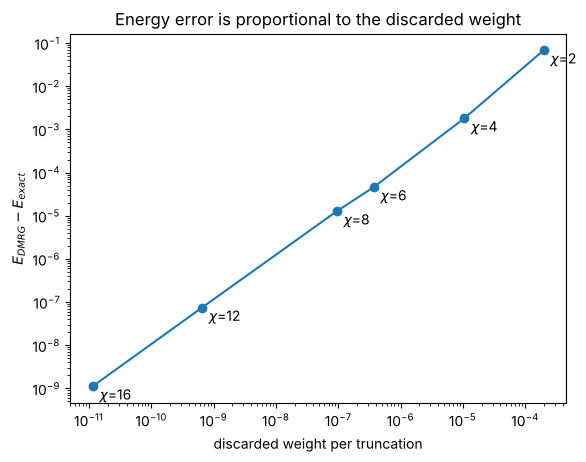

In [5]:
chis = [2, 4, 6, 8, 12, 16]
errs, discs = [], []
for chi in chis:
    r = dmrg.dmrg(dmrg.tfim_mpo(L, h), chi_max=chi, n_sweeps=4)
    errs.append(r["energy"] - E_exact)
    discs.append(r["discarded"])
plt.loglog(discs, errs, "o-")
for chi, x, y in zip(chis, discs, errs, strict=True):
    plt.annotate(f"$\\chi$={chi}", (x, y), textcoords="offset points", xytext=(5, -10))
plt.xlabel("discarded weight per truncation")
plt.ylabel("$E_{DMRG} - E_{exact}$")
plt.title("Energy error is proportional to the discarded weight");

The energy error tracks the discarded weight $\sum_{a>\chi}S_a^2$, roughly linearly. This is the standard way to extrapolate DMRG energies when the exact answer is not known.

## Entanglement at criticality: measuring $c = 1/2$

For an open critical chain, conformal field theory predicts (Calabrese and Cardy, [arXiv:hep-th/0405152](https://arxiv.org/abs/hep-th/0405152))

$$S(l) = \frac{c}{6}\log_2\Big[\frac{2L}{\pi}\sin\frac{\pi l}{L}\Big] + \text{const},$$

with central charge $c = 1/2$ for the Ising transition. (Calabrese and Cardy write it with the natural log and $S$ in nats; dividing both sides by $\ln 2$ gives the same formula with $\log_2$ and $S$ in bits.) DMRG hands us $S(l)$ for every cut from the Schmidt values of the final sweep.

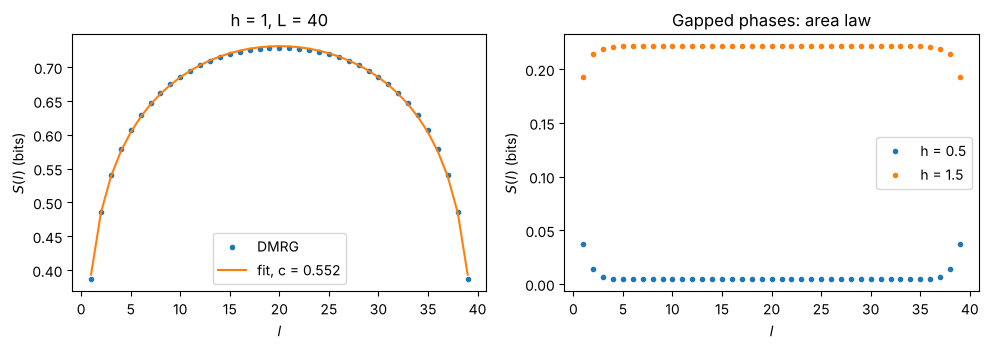

In [6]:
def plot_profiles(L, critical, gapped):
    """critical: entropies at h = 1; gapped: {h: entropies}."""
    c, const = dmrg.central_charge_fit(L, critical)
    l = np.arange(1, L)
    x = np.log2(2 * L / np.pi * np.sin(np.pi * l / L))
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].plot(l, critical, ".", label="DMRG")
    ax[0].plot(l, c / 6 * x + const, "-", label=f"fit, c = {c:.3f}")
    ax[0].set(xlabel="$l$", ylabel="$S(l)$ (bits)", title=f"h = 1, L = {L}")
    ax[0].legend()
    for hh, S in gapped.items():
        ax[1].plot(l, S, ".", label=f"h = {hh}")
    ax[1].set(xlabel="$l$", ylabel="$S(l)$ (bits)", title="Gapped phases: area law")
    ax[1].legend()
    plt.tight_layout()
    plt.show()


L = 40  # quick live run
res = dmrg.dmrg(dmrg.tfim_mpo(L, 1.0), chi_max=24, n_sweeps=2)
gapped = {hh: dmrg.dmrg(dmrg.tfim_mpo(L, hh), chi_max=12, n_sweeps=2)["entropies"] for hh in [0.5, 1.5]}
plot_profiles(L, res["entropies"], gapped)

The full run ($L = 100$, $\chi = 32$ at $h = 1$ and $\chi = 16$ in the gapped phases), loaded from `results/critical_entropy.json`. To remake it: `python scripts/make_results.py critical_entropy`.

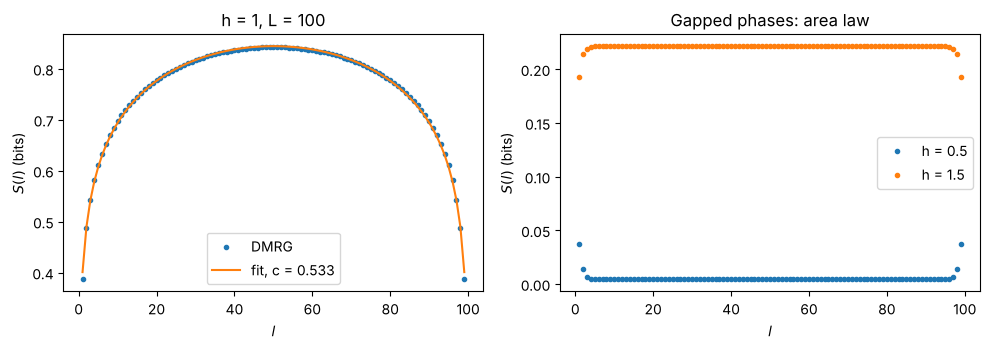

E error at L = 100: 8.5e-11


In [7]:
full = json.load(open("../results/critical_entropy.json"))
crit, *gap = full["runs"]
plot_profiles(full["L"], np.array(crit["entropies"]), {r["h"]: r["entropies"] for r in gap})
print(f"E error at L = {full['L']}: {crit['energy'] - crit['exact']:.1e}")

The fit gives $c \approx 0.5$ (the small deviation comes from the open boundaries, which make $S(l)$ alternate between even and odd $l$). In the gapped phases $S(l)$ saturates (area law). At $h = 0.5$ it is almost zero: in the ordered phase the cat state and the two symmetry-broken states $|\!\to\to\cdots\rangle$, $|\!\leftarrow\leftarrow\cdots\rangle$ are degenerate up to $e^{-L}$, and DMRG lands on a symmetry-broken one, which has the least entanglement. (Compare notebook 1, where exact diagonalization gave the cat with $S \approx 1$ bit.)

## Exercises

1. Start from a product state instead of a random MPS. Does DMRG still converge? Why can two-site DMRG grow the bond dimension, while one-site DMRG cannot without help? (See White, [arXiv:cond-mat/0508709](https://arxiv.org/abs/cond-mat/0508709).)
2. Measure $\langle X_{L/4} X_{L/4+r}\rangle$ at $h = 1$ and check the power law $r^{-1/4}$ (far from the edges).
3. Find the first excited state by adding a penalty $w|\psi_0\rangle\langle\psi_0|$ to $H_\text{eff}$, and compare the gap with the free-fermion result.